In [39]:
import os
import textwrap
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from helpers.alibaba import inject_billed_alibaba, load_all_billed_alibaba
from helpers.aws import inject_billed_aws, load_all_billed_aws
from helpers.azure import inject_billed_azure, load_all_billed_azure
from helpers.benchmark import load_records_from_directory, metric_for_benchmark, remove_cold_starts, trim_on_benchmark
from helpers.cost import calculate_cost
from helpers.cpus import get_cpu_palette, shorten_cpu_name
from helpers.gcp import inject_billed_gcp, load_all_billed_gcp
from helpers.style import use_paper_style

use_paper_style()
pd.set_option("display.float_format", "{:.1f}".format)

LOG_DIR = "data/stage_c"
PARQUET_CACHE = "cache/stage_c.parquet"

LOCAL_WEEK_START = "2025-12-01"
LOCAL_WEEK_END   = "2025-12-08"

PROVIDERS = ["aws", "azure", "gcp", "alibaba"]
PROVIDER_LABEL = {"aws": "AWS", "azure": "Azure", "gcp": "GCF", "alibaba": "Alibaba"}

BENCHMARKS = ["matmul", "sha256", "json", "gzip", "aesCtr"]
BENCHMARK_ORDER = ["gzip", "json", "aesCtr", "sha256", "matmul"]
BENCHMARK_LABEL = {"matmul": "MatMul", "sha256": "SHA-256", "aesCtr": "AES-CTR", "gzip": "Gzip", "json": "JSON"}
WORKLOAD_ORDER = [BENCHMARK_LABEL[b] for b in BENCHMARK_ORDER]

STAGE_C_CONFIGS = [
    ("aws", 512, BENCHMARKS),
    ("gcp", 512, BENCHMARKS),
    ("alibaba", 512, BENCHMARKS),
    ("azure", 512, BENCHMARKS),
]


cache_path = Path(PARQUET_CACHE)
if cache_path.exists():
    print(f"Loading cached dataframe from {cache_path} ...")
    df_raw = pd.read_parquet(cache_path)
else:
    print("Cache not found – loading from raw directory ...")
    df_raw = load_records_from_directory(LOG_DIR)
    print(f"Loaded {len(df_raw)} total records from Stage C experiments.")
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    df_raw.to_parquet(cache_path, index=False)
    print(f"Wrote cache to {cache_path}")

df_raw = df_raw.copy()
df_raw["timestamp"] = pd.to_datetime(df_raw["timestamp"], utc=True)
df_us_east_local = df_raw[
    (df_raw["provider"].isin(["aws", "gcp", "alibaba"])) &
    (df_raw["timestamp"].dt.tz_convert("America/New_York") >= pd.Timestamp(LOCAL_WEEK_START, tz="America/New_York")) &
    (df_raw["timestamp"].dt.tz_convert("America/New_York") <  pd.Timestamp(LOCAL_WEEK_END,   tz="America/New_York"))
].copy()

df_berlin_local = df_raw[
    (df_raw["provider"] == "azure") &
    (df_raw["timestamp"].dt.tz_convert("Europe/Berlin") >= pd.Timestamp(LOCAL_WEEK_START, tz="Europe/Berlin")) &
    (df_raw["timestamp"].dt.tz_convert("Europe/Berlin") <  pd.Timestamp(LOCAL_WEEK_END,   tz="Europe/Berlin"))
].copy()

df_time_trimmed = pd.concat([df_us_east_local, df_berlin_local], ignore_index=True)

print("Rows total:", len(df_raw))
print("Rows after LOCAL week filter (provider-aware):", len(df_time_trimmed))

df = remove_cold_starts(df_time_trimmed)

allowed = {
    (p, mem, b)
    for (p, mem, benchmarks) in STAGE_C_CONFIGS
    for b in benchmarks
}
df = df[
    df.apply(lambda row: (row["provider"], row["memory_size_mb"], row["benchmark_type"]) in allowed, axis=1)
].copy()

def _slot_bin_stage_c_utc(ts: pd.Series) -> pd.Series:
    ts = pd.to_datetime(ts, utc=True)
    return (ts + pd.Timedelta(hours=1)).dt.floor("6h") - pd.Timedelta(hours=1)
df["slot_utc"] = _slot_bin_stage_c_utc(df["timestamp"])

def _provider_local_tz(provider: str) -> str:
    return "Europe/Berlin" if provider == "azure" else "America/New_York"

df["local_tz"] = df["provider"].apply(_provider_local_tz)
df["slot_local"] = df.apply(lambda row: row["slot_utc"].tz_convert(row["local_tz"]), axis=1 )

outlier_trimmed_df = pd.DataFrame()
for provider, mem_size, benchmarks in STAGE_C_CONFIGS:
    for benchmark in benchmarks:
        config_df = df[
            (df["provider"] == provider) &
            (df["memory_size_mb"] == mem_size) &
            (df["benchmark_type"] == benchmark)
        ].copy()
        trimmed_config_df = trim_on_benchmark(config_df, group_on_timestamp=True, benchmark=benchmark)
        outlier_trimmed_df = pd.concat([outlier_trimmed_df, trimmed_config_df], ignore_index=True)
        

print(f"\nRows after CPU filtering: {len(df)}")
print("\nRecords per provider:")
print(df.groupby(["provider"]).size())
trimmed_df = outlier_trimmed_df.copy()
print(f"\nRows after outlier trimming: {len(trimmed_df)}")
print("\nRecords per provider:")
print(trimmed_df.groupby(["provider"]).size())


df["billed_duration_ms"] = np.nan
df = inject_billed_aws(df, load_all_billed_aws(f"{LOG_DIR}/billed/aws"))
df = inject_billed_gcp(df, load_all_billed_gcp(f"{LOG_DIR}/billed/gcp"))
df = inject_billed_alibaba(df, load_all_billed_alibaba(f"{LOG_DIR}/billed/alibaba"))
df = inject_billed_azure(df, load_all_billed_azure(f"{LOG_DIR}/billed/azure"))
df["billed_duration_ms"] = pd.to_numeric(df["billed_duration_ms"], errors="coerce")

Loading cached dataframe from cache/stage_c.parquet ...
Rows total: 1790501
Rows after LOCAL week filter (provider-aware): 1392567

Rows after CPU filtering: 964092

Records per provider:
provider
alibaba    236319
aws        237130
azure      249542
gcp        241101
dtype: int64

Rows after outlier trimming: 953312

Records per provider:
provider
alibaba    233732
aws        234379
azure      246846
gcp        238355
dtype: int64
📥 Loaded 449996 billed AWS records from 45 files.
✅ All AWS entries matched billed durations.
📥 Loaded 450000 billed GCP records from 45 files.
✅ All GCP entries matched billed durations.
📥 Loaded 514007 billed Alibaba records from 5 files.
✅ All Alibaba entries matched billed durations.
📥 Loaded 485673 billed Azure records from 5 files.
⚠️ 3 Azure entries have no billed duration match.


Saved: plots/stage_c/violin_grid_512mb.pdf


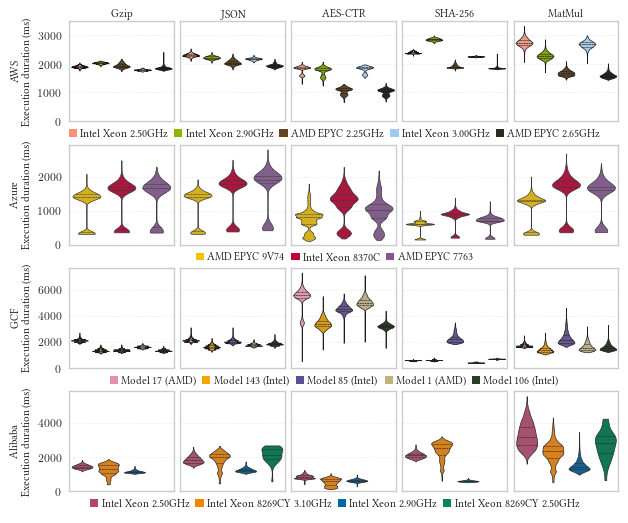

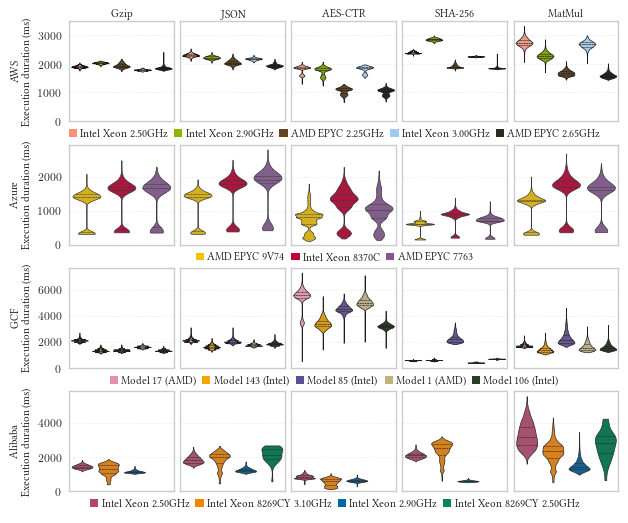

In [40]:
def plot_violin_grid(
    df: pd.DataFrame,
    memory_size: int = 512,
    save_path: str | None = None,
    show: bool = True,
):
    n_rows = len(PROVIDERS)
    n_cols = len(BENCHMARK_ORDER)

    provider_palettes = {}
    provider_cpu_orders = {}
    for provider in PROVIDERS:
        d = df[(df["provider"] == provider) & (df["memory_size_mb"] == memory_size)].copy()
        cpu_order = d["cpu_type"].value_counts().index.tolist()
        palette = get_cpu_palette(cpu_order, provider=provider)
        provider_cpu_orders[provider] = cpu_order
        provider_palettes[provider] = {shorten_cpu_name(c): palette.get(c, "#333333") for c in cpu_order}

    fig = plt.figure(figsize=(7.09, 5))
    subfigs = fig.subfigures(n_rows, 1, hspace=-0.05)

    for row_idx, provider in enumerate(PROVIDERS):
        subfig = subfigs[row_idx]
        axes = subfig.subplots(1, n_cols, sharey=True)
        subfig.subplots_adjust(wspace=0.06)

        d = df[
            (df["provider"] == provider)
            & (df["memory_size_mb"] == memory_size)
            & (df["benchmark_type"].isin(BENCHMARK_ORDER))
        ].copy()

        d["exec_ms"] = np.nan
        for b in BENCHMARK_ORDER:
            mcol = metric_for_benchmark(b)
            mask = d["benchmark_type"] == b
            d.loc[mask, "exec_ms"] = pd.to_numeric(d.loc[mask, mcol], errors="coerce")

        d = d.dropna(subset=["cpu_type", "exec_ms"])
        d = d[d["exec_ms"] > 0]

        provider_max = np.ceil(d["exec_ms"].max() * 1.05)

        cpu_order_short = [shorten_cpu_name(c) for c in provider_cpu_orders[provider]]
        palette_short = provider_palettes[provider]

        for col_idx, benchmark in enumerate(BENCHMARK_ORDER):
            ax = axes[col_idx]
            sub = d[d["benchmark_type"] == benchmark].copy()
            sub["CPU"] = sub["cpu_type"].apply(shorten_cpu_name)

            sns.violinplot(
                data=sub,
                x="CPU",
                y="exec_ms",
                hue="CPU",
                order=cpu_order_short,
                palette=palette_short,
                density_norm="width",
                cut=0,
                inner="quartile",
                linewidth=0.5,
                legend=False,
                ax=ax,
            )

            ax.set_ylim(0, provider_max)
            ax.set_xticks([])
            ax.set_xlabel("")
            ax.grid(True, axis="y", linestyle="--", alpha=0.35, linewidth=0.5)
            ax.grid(False, axis="x")
            ax.set_axisbelow(True)
            ax.tick_params(axis="y", labelsize=8, length=2)

            if row_idx == 0:
                ax.set_title(BENCHMARK_LABEL[benchmark], fontsize=8, fontweight="bold", pad=3)

            if col_idx == 0:
                ax.set_ylabel(
                    f"{PROVIDER_LABEL[provider]}\nExecution duration (ms)",
                    fontsize=8,
                    fontweight="bold",
                    labelpad=4,
                )
                ax.tick_params(axis="y", labelsize=8, length=2, labelleft=True)
            else:
                ax.set_ylabel("")
                ax.tick_params(axis="y", labelsize=8, length=2, labelleft=False)

        handles = [
            Patch(facecolor=palette_short[c], edgecolor="none", label=c)
            for c in cpu_order_short
        ]
        subfig.legend(
            handles,
            cpu_order_short,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.1),
            ncol=len(cpu_order_short),
            fontsize=8,
            frameon=False,
            handlelength=0.75,
            handletextpad=0.3,
            columnspacing=0.5,
            borderpad=0.3,
        )

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight", format="pdf", dpi=300)
        print(f"Saved: {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig


plot_violin_grid(
    df=trimmed_df,
    memory_size=512,
    save_path="plots/stage_c/violin_grid_512mb.pdf",
)

Provider Workload   CV  eta2
     AWS     Gzip  3.3  54.0
     AWS     JSON  4.7  72.0
     AWS  AES-CTR 13.5  76.4
     AWS  SHA-256 10.1  97.2
     AWS   MatMul 17.5  93.3
 Alibaba     Gzip 13.6  22.9
 Alibaba     JSON 16.9  20.7
 Alibaba  AES-CTR 23.7  44.7
 Alibaba  SHA-256 21.3  80.1
 Alibaba   MatMul 29.7  46.1
   Azure     Gzip 44.2   1.6
   Azure     JSON 44.3   3.8
   Azure  AES-CTR 48.7  12.2
   Azure  SHA-256 40.5   8.1
   Azure   MatMul 46.0   5.2
     GCF     Gzip 23.0  90.2
     GCF     JSON 13.8  71.0
     GCF  AES-CTR 21.6  71.8
     GCF  SHA-256 71.6  96.5
     GCF   MatMul 24.1  56.4
Saved: plots/stage_c/cv_eta2_combined.pdf


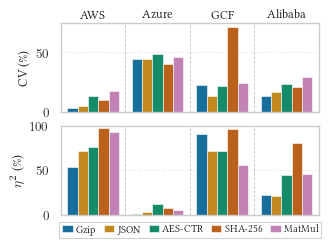

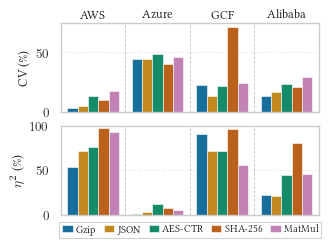

In [41]:
def _calculate_eta2_cpu_raw(df, provider, benchmark, memory_size=512):
    metric = metric_for_benchmark(benchmark)
    d = df[
        (df["provider"].str.lower() == provider.lower())
        & (df["memory_size_mb"] == memory_size)
        & (df["benchmark_type"] == benchmark)
    ].copy()

    d = d.dropna(subset=["cpu_type", metric])
    d["execution_time_ms"] = pd.to_numeric(d[metric], errors="coerce")
    d = d.dropna(subset=["execution_time_ms"])

    if d.empty or (d["execution_time_ms"] <= 0).any():
        return np.nan
    if d["cpu_type"].nunique() < 2:
        return np.nan

    d["log_exec_time"] = np.log(d["execution_time_ms"])
    y = d["log_exec_time"].to_numpy(float)

    grand_mean = y.mean()
    ss_total = float(((y - grand_mean) ** 2).sum())
    if ss_total <= 0:
        return np.nan

    group_means = d.groupby("cpu_type")["log_exec_time"].mean()
    group_sizes = d.groupby("cpu_type")["log_exec_time"].size()
    ss_between = float((group_sizes * (group_means - grand_mean) ** 2).sum())

    return (ss_between / ss_total) * 100.0


def plot_cv_eta2_combined_raw(
    trimmed_df: pd.DataFrame,
    memory_size: int = 512,
    save_path: str | None = None,
    show: bool = True,
):
    cv_rows = []
    for provider in PROVIDERS:
        for benchmark, label in BENCHMARK_LABEL.items():
            sub = trimmed_df[
                (trimmed_df["provider"] == provider)
                & (trimmed_df["benchmark_type"] == benchmark)
                & (trimmed_df["memory_size_mb"] == memory_size)
            ]
            metric = metric_for_benchmark(benchmark)
            cv = (sub[metric].std() / sub[metric].mean()) * 100.0 if len(sub) > 0 else np.nan
            cv_rows.append({
                "Provider": PROVIDER_LABEL[provider],
                "Workload": label,
                "CV": cv,
            })
    cv_df = pd.DataFrame(cv_rows)

    eta_rows = []
    for provider in PROVIDERS:
        for benchmark, label in BENCHMARK_LABEL.items():
            eta2 = _calculate_eta2_cpu_raw(trimmed_df, provider, benchmark, memory_size)
            eta_rows.append({
                "Provider": PROVIDER_LABEL[provider],
                "Workload": label,
                "eta2": eta2,
            })
    eta_df = pd.DataFrame(eta_rows)

    combined_df = pd.merge(
        cv_df,
        eta_df,
        on=["Provider", "Workload"],
        how="outer"
    )

    combined_df["Workload"] = pd.Categorical(
        combined_df["Workload"],
        categories=WORKLOAD_ORDER,
        ordered=True
    )
    combined_df = combined_df.sort_values(["Provider", "Workload"])

    print(combined_df.to_string(index=False))


    provider_order = [PROVIDER_LABEL[p] for p in PROVIDERS]

    fig = plt.figure(figsize=(3.33, 2.5))
    gs = gridspec.GridSpec(
        2, 1,
        height_ratios=[1, 1],
        hspace=0.15,
        figure=fig,
    )
    ax_cv = fig.add_subplot(gs[0])
    ax_eta = fig.add_subplot(gs[1], sharex=ax_cv)

    palette = sns.color_palette("colorblind", n_colors=len(WORKLOAD_ORDER))

    sns.barplot(
        data=cv_df,
        x="Provider", y="CV",
        hue="Workload",
        hue_order=WORKLOAD_ORDER,
        order=provider_order,
        palette=palette,
        ax=ax_cv,
        linewidth=0.4,
        edgecolor="white",
    )
    sns.barplot(
        data=eta_df,
        x="Provider", y="eta2",
        hue="Workload",
        hue_order=WORKLOAD_ORDER,
        order=provider_order,
        palette=palette,
        ax=ax_eta,
        linewidth=0.4,
        edgecolor="white",
    )

    for ax in (ax_cv, ax_eta):
        for i in range(len(provider_order) - 1):
            ax.axvline(
                i + 0.5,
                color="#888888",
                linewidth=0.6,
                linestyle="--",
                alpha=0.5,
                zorder=0,
            )

    ax_cv.set_ylabel("CV (\\%)", fontweight="bold")
    ax_cv.set_xlabel("")
    ax_cv.tick_params(axis="x", labelbottom=False, length=0)
    ax_cv.grid(True, axis="y", linestyle="--", alpha=0.3)
    ax_cv.grid(False, axis="x")
    ax_cv.set_axisbelow(True)

    for i, prov_label in enumerate(provider_order):
        ax_cv.text(
            i, 1.02, prov_label,
            ha="center", va="bottom",
            fontweight="bold",
            fontsize=9,
            transform=ax_cv.get_xaxis_transform(),
        )

    ax_eta.set_ylabel("$\\eta^2$ (\\%)", fontweight="bold")
    ax_eta.set_xlabel("")
    ax_eta.set_ylim(0, 100)
    ax_eta.tick_params(axis="x", labelbottom=False, length=0)
    ax_eta.grid(True, axis="y", linestyle="--", alpha=0.3)
    ax_eta.grid(False, axis="x")
    ax_eta.set_axisbelow(True)

    ax_cv.get_legend().remove()
    eta_legend = ax_eta.get_legend()
    handles, labels = eta_legend.legend_handles, [t.get_text() for t in eta_legend.get_texts()]
    eta_legend.remove()

    leg = ax_eta.legend(
        handles, labels,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.02),
        fontsize=7.5,
        frameon=True,
        framealpha=0.92,
        ncol=5,
        edgecolor="#cccccc",
        fancybox=False,
        handlelength=1.0,
        handletextpad=0.3,
        columnspacing=0.8,
        borderpad=0.3,
    )

    leg._legend_box.align = "center"


    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight", format="pdf", dpi=300)
        print(f"Saved: {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig


plot_cv_eta2_combined_raw(
    trimmed_df=trimmed_df,
    memory_size=512,
    save_path="plots/stage_c/cv_eta2_combined.pdf",
)

                         cheapest  costliest  actual
provider benchmark_type                             
alibaba  aesCtr               6.6       10.9     9.9
         gzip                12.9       16.3    15.6
         json                13.7       19.9    19.4
         matmul              16.7       34.0    30.6
         sha256               7.9       24.0    22.3
aws      aesCtr              11.0       17.7    17.2
         gzip                17.4       19.4    18.5
         json                18.4       21.5    21.2
         matmul              16.1       25.7    23.4
         sha256              17.9       26.5    22.4
azure    aesCtr              22.3       30.5    24.8
         gzip                30.4       35.8    31.8
         json                29.5       38.6    31.5
         matmul              28.2       35.6    30.5
         sha256              19.2       23.1    20.4
gcp      aesCtr              34.9       55.3    46.3
         gzip                17.3       25.4  

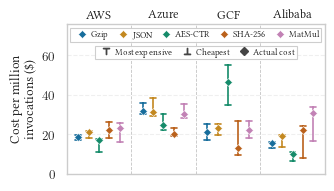

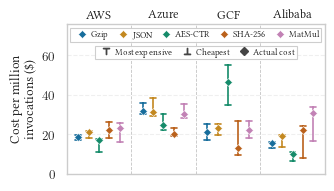

In [ ]:
def plot_cost_per_cpu(df, memory_size=512, save_path=None, show=True):
    c = df[df["memory_size_mb"] == memory_size].dropna(subset=["billed_duration_ms", "cpu_type"]).copy()
    c["cost"] = [calculate_cost(p, memory_size, d) * 1e6 for p, d in zip(c["provider"], c["billed_duration_ms"])]
    keys = ["provider", "benchmark_type"]
    g = c.groupby(keys + ["cpu_type"])["cost"].agg(["mean", "size"])
    g = g[g["size"] / g.groupby(keys)["size"].transform("sum") >= 0.01]
    cost = pd.DataFrame({
        "cheapest": g.groupby(keys)["mean"].min(),
        "costliest": g.groupby(keys)["mean"].max(),
        "actual": c.groupby(keys)["cost"].mean(),
    })
    print(cost.round(2).to_string())

    wide = cost.reset_index()
    wide["Provider"] = wide["provider"].map(PROVIDER_LABEL)
    wide["Workload"] = wide["benchmark_type"].map(BENCHMARK_LABEL)
    span = wide.melt(id_vars=["Provider", "Workload"], value_vars=["cheapest", "costliest"], value_name="usd")

    order = [PROVIDER_LABEL[p] for p in PROVIDERS]
    palette = [sns.desaturate(c, 0.75) for c in sns.color_palette("colorblind", n_colors=len(WORKLOAD_ORDER))]
    kw = dict(x="Provider", hue="Workload", order=order, hue_order=WORKLOAD_ORDER, palette=palette)

    fig, ax = plt.subplots(figsize=(3.33, 1.95))
    sns.pointplot(data=span, y="usd", **kw, dodge=0.64, linestyle="none", marker="", legend=False, ax=ax,
                  errorbar=lambda v: (v.min(), v.max()), capsize=0.09, err_kws={"linewidth": 1.2})
    sns.stripplot(data=wide, y="actual", **kw, dodge=True, jitter=False, marker="D", size=4,
                  edgecolor="white", linewidth=0.4, ax=ax)

    for i in range(len(order) - 1):
        ax.axvline(i + 0.5, color="#888888", linewidth=0.6, linestyle="--", alpha=0.5, zorder=0)
    ax.set_ylim(0, 76)
    ax.set_yticks([0, 20, 40, 60])
    ax.set_ylabel("Cost per million\ninvocations (\\$)", fontweight="bold")
    ax.set_xlabel("")
    ax.set_xticks(range(len(order)))
    ax.tick_params(axis="x", labelbottom=False, length=0)
    for i, label in enumerate(order):
        ax.text(i, 1.02, label, ha="center", va="bottom", fontweight="bold", fontsize=9,
                transform=ax.get_xaxis_transform())
    ax.grid(True, axis="y", linestyle="--", alpha=0.3)
    ax.grid(False, axis="x")

    legend_kw = dict(fontsize=6.5, frameon=True, framealpha=0.95, edgecolor="#cccccc", fancybox=False,
                     handletextpad=0.0, columnspacing=0.6, borderpad=0.3)
    handles, labels = ax.get_legend_handles_labels()
    ax.add_artist(ax.legend(handles, labels, loc="upper center", ncol=5, **legend_kw))
    marks = [(r"$\top$", "Most expensive"), (r"$\bot$", "Cheapest"), ("D", "Actual cost")]
    ax.legend(handles=[Line2D([], [], ls="none", marker=m, ms=4.5, color="#444444", label=l) for m, l in marks],
              loc="upper center", bbox_to_anchor=(0.5, 0.885), ncol=3, **legend_kw)

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight", format="pdf", dpi=300)
        print(f"Saved: {save_path}")
    plt.show() if show else plt.close(fig)
    return fig


plot_cost_per_cpu(df, memory_size=512, save_path="plots/stage_c/cost_per_cpu.pdf")

Saved: plots/stage_c/azure_composition_over_time.pdf


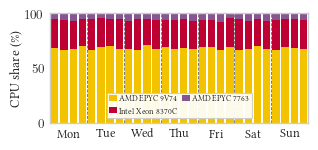

Saved: plots/stage_c/gcp_composition_over_time.pdf


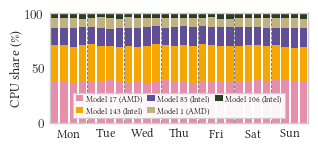

Saved: plots/stage_c/alibaba_composition_over_time.pdf


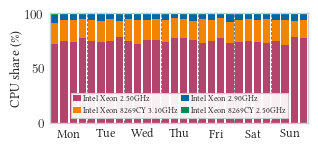

Saved: plots/stage_c/aws_composition_over_time.pdf


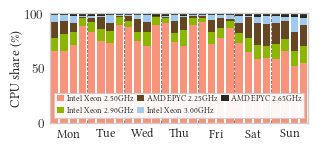

In [43]:
def plot_cpu_composition_over_time_single(
    df: pd.DataFrame,
    provider: str = "aws",
    memory_size: int = 512,
    benchmarks: list[str] | None = None,
    save_path: str | None = None,
    show: bool = True,
):
    d = df[
        (df["provider"] == provider)
        & (df["memory_size_mb"] == memory_size)
        & (df["benchmark_type"].isin(benchmarks))
    ].copy()

    d = d.sort_values("slot_local")
    unique_slots = pd.Index(d["slot_local"].unique()).sort_values()
    slot_to_idx = {slot: i for i, slot in enumerate(unique_slots)}
    d["slot_idx"] = d["slot_local"].map(slot_to_idx)

    dist_counts = d.groupby(["slot_idx", "cpu_type"]).size().unstack(fill_value=0)
    dist_pct = dist_counts.div(dist_counts.sum(axis=1), axis=0) * 100.0

    cpu_order = dist_counts.sum(axis=0).sort_values(ascending=False).index.tolist()
    dist_pct = dist_pct.reindex(columns=cpu_order)

    palette = get_cpu_palette(cpu_order, provider=provider)

    local_days = pd.Series(unique_slots.date)
    day_bounds = {}
    for i, day in enumerate(local_days):
        day_bounds.setdefault(day, []).append(i)

    fig, ax = plt.subplots(figsize=(3.33, 1.5))
    fig.subplots_adjust(top=0.95, bottom=0.22)

    legend_handles = []
    legend_labels = []

    bottom = np.zeros(len(dist_pct))
    for cpu in dist_pct.columns:
        heights = dist_pct[cpu].values
        color = palette.get(cpu, "#333333")
        ax.bar(
            dist_pct.index,
            heights,
            bottom=bottom,
            width=0.8,
            color=color,
            edgecolor="none",
        )
        bottom += heights
        legend_handles.append(
            Patch(facecolor=color, edgecolor="none")
        )
        legend_labels.append(shorten_cpu_name(cpu))

    ax.set_ylabel("CPU share (\\%)", fontweight="bold", labelpad=2)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 50, 100])
    ax.tick_params(axis="y", pad=4, color="#888888", length=0)

    ax.set_xticks([])
    ax.set_xlim(-0.5, len(unique_slots) - 0.5)

    for day, idxs in day_bounds.items():
        center = (idxs[0] + idxs[-1]) / 2
        ax.text(
            center, -5,
            pd.Timestamp(day).strftime("%a"),
            ha="center", va="top",
            fontweight="bold",
            transform=ax.transData,
        )
        if idxs[0] > 0:
            ax.axvline(
                idxs[0] - 0.5,
                color="#555555", linestyle="--",
                linewidth=0.6, alpha=0.9,
            )

    ax.grid(False)

    n = len(legend_labels)
    ncol = (n + 1) // 2

    ax.legend(
        legend_handles, legend_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=ncol,
        fontsize=6,
        frameon=True,
        framealpha=0.92,
        edgecolor="#cccccc",
        fancybox=False,
        handlelength=0.9,
        handletextpad=0.3,
        columnspacing=0.5,
        borderpad=0.3,
    )

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight", format="pdf", dpi=300)
        print(f"Saved: {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig


for provider in ["azure", "gcp", "alibaba","aws"]:
    plot_cpu_composition_over_time_single(
        df,
        provider=provider,
        memory_size=512,
        benchmarks=BENCHMARKS,
        save_path=f"plots/stage_c/{provider}_composition_over_time.pdf",
    )


In [44]:
KEY_FLAGS = {
    "sha_ni": "SHA-NI",
    "aes": "AES-NI", 
    "vaes": "VAES",
    "avx512f": "AVX512",
    "avx512ifma": "IFMA",
    "avx512_vnni": "VNNI",
}

def check_flag(flags, flag_name):
    if isinstance(flags, (list, np.ndarray)):
        return flag_name in flags
    return flag_name in str(flags).split()

results = []
for provider in PROVIDERS:
    provider_df = df[df["provider"] == provider]
    
    for cpu in sorted(provider_df["cpu_type"].unique()):
        flags = provider_df[provider_df["cpu_type"] == cpu]["flags"].iloc[0]
        
        row = {"Provider": provider.upper(), "CPU": cpu}
        for flag, name in KEY_FLAGS.items():
            row[name] = "yes" if check_flag(flags, flag) else "no"
        results.append(row)


cap_df = pd.DataFrame(results)

pd.set_option('display.max_colwidth', 40)
pd.set_option('display.width', 120)
print(cap_df.to_markdown(index=False))

| Provider   | CPU                       | SHA-NI   | AES-NI   | VAES   | AVX512   | IFMA   | VNNI   |
|:-----------|:--------------------------|:---------|:---------|:-------|:---------|:-------|:-------|
| AWS        | AMD EPYC 2.25GHz          | no       | yes      | no     | no       | no     | no     |
| AWS        | AMD EPYC 2.65GHz          | no       | yes      | no     | no       | no     | no     |
| AWS        | Intel Xeon 2.50GHz        | no       | yes      | no     | no       | no     | no     |
| AWS        | Intel Xeon 2.90GHz        | no       | yes      | no     | no       | no     | no     |
| AWS        | Intel Xeon 3.00GHz        | no       | yes      | no     | no       | no     | no     |
| AZURE      | AMD EPYC 7763             | yes      | yes      | yes    | no       | no     | no     |
| AZURE      | AMD EPYC 9V74             | yes      | yes      | yes    | yes      | yes    | yes    |
| AZURE      | Intel Xeon 8370C          | yes      | yes      | yes    |

Saved: plots/stage_c/within_cpu_vs_overall_cv_by_workload_512mb.pdf


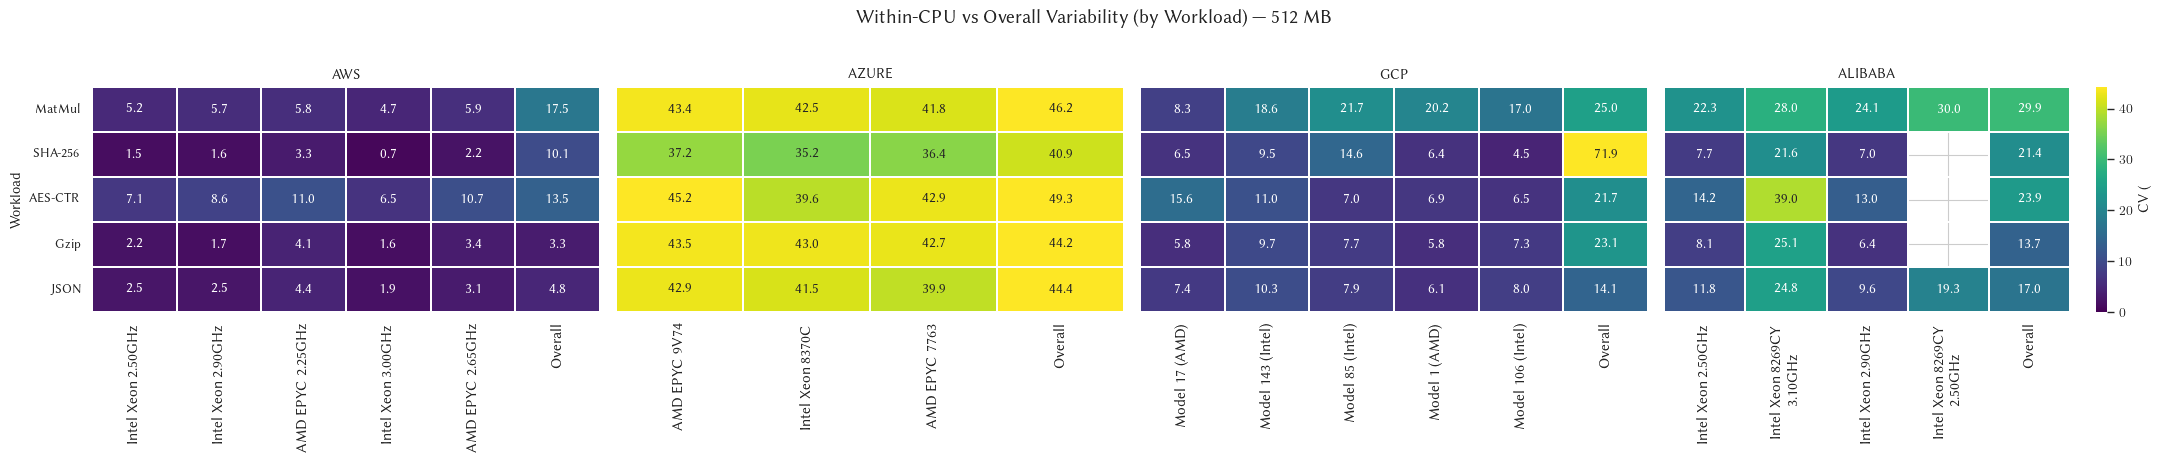

In [45]:
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)


def plot_stage_c_cv_heatmap_by_workload(
    df: pd.DataFrame,
    memory_size: int = 512,
    providers: list[str] = None,
    workloads: list[str] = None,
    save_path: str | None = None,
    show: bool = True,
    gamma_for_vmax: float = 0.95,
    figsize: tuple = None,
) -> plt.Figure:
    providers = providers or ["aws", "azure", "gcp", "alibaba"]
    workloads = workloads or ["matmul", "sha256", "aesCtr", "gzip", "json"]

    d0 = df.copy()
    d0["provider"] = d0["provider"].astype(str).str.lower()
    d0["benchmark_type"] = d0["benchmark_type"].astype(str)
    d0 = d0[
        (d0["memory_size_mb"] == memory_size)
        & (d0["provider"].isin(providers))
        & (d0["benchmark_type"].isin(workloads))
    ].copy()
    if d0.empty:
        raise ValueError("No rows left after filtering (memory/provider/workload).")

    parts = []
    for w in workloads:
        mcol = metric_for_benchmark(w)
        if mcol not in d0.columns:
            if "runtime_ms" not in d0.columns:
                raise ValueError(f"Missing metric column '{mcol}' and 'runtime_ms'.")
            mcol = "runtime_ms"

        sub = d0[d0["benchmark_type"] == w][["provider", "benchmark_type", "cpu_type", mcol]].copy()
        sub["metric"] = pd.to_numeric(sub[mcol], errors="coerce")
        parts.append(sub[["provider", "benchmark_type", "cpu_type", "metric"]])

    d = pd.concat(parts, ignore_index=True).dropna(subset=["cpu_type", "metric"])

    cpu_stats = d.groupby(["provider", "benchmark_type", "cpu_type"])["metric"].agg(["mean", "std"]).reset_index()
    cpu_stats["cv"] = (cpu_stats["std"] / cpu_stats["mean"]) * 100.0

    overall_stats = d.groupby(["provider", "benchmark_type"])["metric"].agg(["mean", "std"]).reset_index()
    overall_stats["cv"] = (overall_stats["std"] / overall_stats["mean"]) * 100.0

    cpu_stats["cv"] = cpu_stats["cv"].replace([np.inf, -np.inf], np.nan)
    overall_stats["cv"] = overall_stats["cv"].replace([np.inf, -np.inf], np.nan)

    all_cv = pd.concat([cpu_stats["cv"], overall_stats["cv"]], ignore_index=True)
    all_cv = all_cv[np.isfinite(all_cv.to_numpy())]
    vmax = float(np.nanpercentile(all_cv, gamma_for_vmax * 100.0)) if len(all_cv) else 1.0
    vmax = max(vmax, 1.0)

    vmin = 0.0
    if figsize is None:
        figsize = (5.5 * len(providers), 4.5)

    fig, axes = plt.subplots(1, len(providers), figsize=figsize, sharey=True)
    if len(providers) == 1:
        axes = [axes]

    for i, prov in enumerate(providers):
        ax = axes[i]

        sub_cpu = cpu_stats[cpu_stats["provider"] == prov]
        sub_overall = overall_stats[overall_stats["provider"] == prov]

        pivot = (
            sub_cpu.pivot_table(index="benchmark_type", columns="cpu_type", values="cv", aggfunc="mean")
            .reindex(index=workloads)
        )

        pivot.index = [BENCHMARK_LABEL.get(w, w) for w in workloads]

        overall_series = sub_overall.set_index("benchmark_type")["cv"].reindex(workloads).to_numpy()
        pivot["Overall"] = overall_series

        cpu_order = d[d["provider"] == prov]["cpu_type"].value_counts().index.tolist()
        cols = [c for c in cpu_order if c in pivot.columns] + ["Overall"]
        pivot = pivot[cols]


        sns.heatmap(
            pivot,
            ax=ax,
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            annot=True,
            fmt=".1f",
            linewidths=0.3,
            linecolor="white",
            cbar=(i == len(providers) - 1),
            cbar_kws={"label": "CV (%)"},
        )

        wrap = lambda s: "\n".join(textwrap.wrap(str(s), width=20))
        ax.set_xticklabels(
            ["Overall" if c == "Overall" else wrap(c) for c in pivot.columns],
            rotation=90,
            ha="center",
        )


        for t in ax.get_xticklabels():
            if t.get_text() == "Overall":
                t.set_fontweight("bold")

        ax.set_title(prov.upper(), fontweight="bold")
        ax.set_ylabel("Workload" if i == 0 else "")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=90, labelsize=11)
        ax.tick_params(axis="y", rotation=0)

    fig.suptitle(
        f"Within-CPU vs Overall Variability (by Workload) — {memory_size} MB",
        fontsize=14, fontweight="bold", y=1.02
    )

    plt.tight_layout()

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, bbox_inches="tight", dpi=150)
        print(f"Saved: {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig


fig = plot_stage_c_cv_heatmap_by_workload(
    df,
    memory_size=512,
    providers=["aws", "azure", "gcp", "alibaba"],
    workloads=["matmul", "sha256", "aesCtr", "gzip", "json"],
    save_path="plots/stage_c/within_cpu_vs_overall_cv_by_workload_512mb.pdf",
)

In [46]:
def summarize_stage_c(df: pd.DataFrame, trimmed_df: pd.DataFrame, memory_size: int = 512) -> pd.DataFrame:
    """
    One row per provider, workload, and CPU type, plus an "all" row per provider and workload.
    Share and cost use all invocations (as in the composition and cost figures); the duration
    statistics, CV, and eta2 use the trimmed data (as in the violin and CV / eta2 figures).
    x_vs_dom is the median duration relative to the dominant CPU (most instances per provider).
    """
    raw = df[df["memory_size_mb"] == memory_size]
    trim = trimmed_df[trimmed_df["memory_size_mb"] == memory_size]

    dominant = {
        provider: g.groupby("cpu_type")["instance_id"].nunique().idxmax()
        for provider, g in trim.groupby("provider")
    }
    flags = {key: g["flags"].iloc[0] for key, g in raw.groupby(["provider", "cpu_type"])}

    rows = []
    for provider in PROVIDERS:
        for benchmark in BENCHMARK_ORDER:
            metric = metric_for_benchmark(benchmark)
            r_cfg = raw[(raw["provider"] == provider) & (raw["benchmark_type"] == benchmark)].copy()
            t_cfg = trim[(trim["provider"] == provider) & (trim["benchmark_type"] == benchmark)]
            r_cfg["cost"] = [calculate_cost(provider, memory_size, x) * 1e6 for x in r_cfg["billed_duration_ms"]]
            dom_median = t_cfg.loc[t_cfg["cpu_type"] == dominant[provider], metric].median()

            groups = [("all", r_cfg, t_cfg)] + [
                (cpu, r_cfg[r_cfg["cpu_type"] == cpu], t_cfg[t_cfg["cpu_type"] == cpu])
                for cpu in r_cfg["cpu_type"].value_counts().index
            ]
            for cpu, r, t in groups:
                dur = t[metric]
                is_all = cpu == "all"
                rows.append({
                    "provider": PROVIDER_LABEL[provider],
                    "workload": BENCHMARK_LABEL[benchmark],
                    "cpu": cpu if is_all else shorten_cpu_name(cpu) + (" (dom.)" if cpu == dominant[provider] else ""),
                    "sha_ni": "" if is_all else ("yes" if check_flag(flags[(provider, cpu)], "sha_ni") else "no"),
                    "aes_ni": "" if is_all else ("yes" if check_flag(flags[(provider, cpu)], "aes") else "no"),
                    "n": len(t),
                    "share_%": len(r) / len(r_cfg) * 100,
                    "median_ms": dur.median(),
                    "x_vs_dom": np.nan if is_all else dur.median() / dom_median,
                    "mean_ms": dur.mean(),
                    "std_ms": dur.std(),
                    "cv_%": dur.std() / dur.mean() * 100,
                    "p5_ms": dur.quantile(0.05),
                    "p95_ms": dur.quantile(0.95),
                    "eta2_%": _calculate_eta2_cpu_raw(trimmed_df, provider, benchmark, memory_size) if is_all else np.nan,
                    "usd_per_1M": r["cost"].mean(),
                })
    return pd.DataFrame(rows)


def composition_stability(df: pd.DataFrame, memory_size: int = 512) -> pd.DataFrame:
    """CPU share per six-hour slot (all workloads pooled, as in the composition figure), summarized over the week."""
    rows = []
    for provider in PROVIDERS:
        d = df[(df["provider"] == provider) & (df["memory_size_mb"] == memory_size)]
        counts = d.groupby(["slot_local", "cpu_type"]).size().unstack(fill_value=0)
        shares = counts.div(counts.sum(axis=1), axis=0) * 100
        for cpu in shares.mean().sort_values(ascending=False).index:
            rows.append({
                "provider": PROVIDER_LABEL[provider],
                "cpu": shorten_cpu_name(cpu),
                "slots": len(shares),
                "mean_share_%": shares[cpu].mean(),
                "min_share_%": shares[cpu].min(),
                "max_share_%": shares[cpu].max(),
                "std_pp": shares[cpu].std(),
            })
    return pd.DataFrame(rows)


pd.set_option("display.max_rows", 300)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 250)

summary = summarize_stage_c(df, trimmed_df)
print("Per provider, workload, and CPU type (512 MB)")
display(summary)

stability = composition_stability(df)
print("CPU share per six-hour slot over the week")
display(stability)

Per provider, workload, and CPU type (512 MB)


,provider,workload,cpu,sha_ni,aes_ni,n,share_%,median_ms,x_vs_dom,mean_ms,std_ms,cv_%,p5_ms,p95_ms,eta2_%,usd_per_1M
0,AWS,Gzip,all,,,47034,100.0,1906.0,NaN,1917.1,62.9,3.3,1823.4,2040.2,54.0,18.5
1,AWS,Gzip,Intel Xeon 2.50GHz (dom.),no,yes,37037,78.6,1902.0,1.0,1908.3,40.2,2.1,1844.7,1979.3,NaN,18.4
2,AWS,Gzip,Intel Xeon 2.90GHz,no,yes,4561,9.7,2038.5,1.1,2034.0,33.6,1.7,1979.2,2083.4,NaN,19.4
3,AWS,Gzip,AMD EPYC 2.25GHz,no,yes,2731,5.8,1937.1,1.0,1946.7,78.2,4.0,1838.5,2097.8,NaN,18.7
4,AWS,Gzip,Intel Xeon 3.00GHz,no,yes,1979,4.2,1796.5,0.9,1793.0,26.3,1.5,1757.4,1839.1,NaN,17.4
5,AWS,Gzip,AMD EPYC 2.65GHz,no,yes,726,1.6,1843.5,1.0,1856.5,56.1,3.0,1788.0,1953.2,NaN,17.8
6,AWS,JSON,all,,,47013,100.0,2282.6,NaN,2266.4,106.5,4.7,2019.9,2399.1,72.0,21.2
7,AWS,JSON,Intel Xeon 2.50GHz (dom.),no,yes,35405,75.2,2302.8,1.0,2310.6,55.2,2.4,2222.1,2402.5,NaN,21.5
8,AWS,JSON,Intel Xeon 2.90GHz,no,yes,4575,9.7,2220.0,1.0,2219.2,52.8,2.4,2138.3,2300.7,NaN,20.8
9,AWS,JSON,AMD EPYC 2.25GHz,no,yes,4209,9.0,2042.2,0.9,2055.3,85.7,4.2,1923.2,2215.8,NaN,19.5


CPU share per six-hour slot over the week


,provider,cpu,slots,mean_share_%,min_share_%,max_share_%,std_pp
0,AWS,Intel Xeon 2.50GHz,28,74.0,51.8,92.3,12.1
1,AWS,Intel Xeon 2.90GHz,28,10.1,3.2,15.7,3.4
2,AWS,AMD EPYC 2.25GHz,28,9.7,0.8,20.0,6.6
3,AWS,Intel Xeon 3.00GHz,28,4.0,0.5,13.3,3.0
4,AWS,AMD EPYC 2.65GHz,28,2.1,1.1,4.0,0.8
5,Azure,AMD EPYC 9V74,28,68.2,66.2,71.1,1.3
6,Azure,Intel Xeon 8370C,28,26.0,23.4,29.2,1.2
7,Azure,AMD EPYC 7763,28,5.7,4.6,7.9,0.9
8,GCF,Model 17 (AMD),28,38.0,36.1,39.8,0.9
9,GCF,Model 143 (Intel),28,32.5,29.5,34.5,1.1
